# 8. Czas predykcji i złożoność algorytmów dla URL Corpus

Notebook uzupełnia porównanie pięciu algorytmów o wydajność inferencji, czas deserializacji i miary złożoności strukturalnej. Źródłem prawdy są wyłącznie artefakty `staged_url_corpus_v4` oraz stały zbiór testowy V4. Warianty `full` i `selected` są raportowane osobno. Nie występuje trenowanie ani modyfikacja artefaktów.

Metodyka: `random_state=42`, partie 1/32/256/1000, 10 rozgrzewek, 100 powtórzeń, `time.perf_counter_ns()`. Czas deserializacji: 1 rozgrzewka i 30 powtórzeń. Pomiar `classifier-only` oddzielono od skalowania i klasyfikatora.

In [1]:
import importlib
import os
import sys
from pathlib import Path


def locate_backend_root():
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        nested_backend = candidate / 'backend'
        if (candidate / 'config').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
        if (nested_backend / 'config').is_dir() and (nested_backend / 'notebooks').is_dir():
            return nested_backend
    raise FileNotFoundError('Nie znaleziono katalogu backend')


backend_root = locate_backend_root()
notebooks_dir = backend_root / 'notebooks' / 'url_corpus'
os.chdir(notebooks_dir)
sys.path.insert(0, str(backend_root))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/phishing-detector-matplotlib')
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])
print(f'Backend: {backend_root}')


Backend: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend


In [2]:
import gc
import json
import pickle
import platform

import numpy as np
import pandas as pd
import psutil
import sklearn
import tensorflow as tf
import xgboost as xgb

from config.feature_names_config import FeatureConfig
from config.feature_policy import FEATURE_POLICY_VERSION
from config.project_paths import RESULTS_ROOT
from scripts.recheck_url_corpus_models import artifact_filename, load_payload
from utils.benchmark_plots import plot_runtime_results
from utils.research_benchmark import (
    algorithm_complexity,
    classifier_probabilities,
    measure_ns,
    timing_summary_ns,
    validate_staged_payload,
)

RANDOM_STATE = 42
ALGORITHMS = ('logistic_regression', 'random_forest', 'xgboost', 'svm', 'mlp')
MODES = ('full', 'selected')
BATCH_SIZES = (1, 32, 256, 1000)
WARMUPS = 10
REPETITIONS = 100
LOAD_WARMUPS = 1
LOAD_REPETITIONS = 30
MODEL_LABELS = {
    'logistic_regression': 'Regresja Logistyczna',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost',
    'svm': 'SVM',
    'mlp': 'MLP',
}
MODEL_ROOT = backend_root / 'models' / 'staged_url_corpus_v4'
DATA_ROOT = backend_root / 'data' / 'url_corpus' / 'quality_v4_repaired_features'
OUTPUT_DIR = RESULTS_ROOT / 'url_corpus' / 'runtime_complexity'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Wyniki: {OUTPUT_DIR}')


Wyniki: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/runtime_complexity


## Walidacja artefaktów i schematów

Dla każdej pary algorytm–wariant sprawdzane są: nazwy i kolejność cech względem konfiguracji V4, obecność wymaganego skalera, zgodność polityki cech, wariant artefaktu oraz próg decyzyjny. Błąd kontraktu przerywa notebook zamiast tworzyć niemiarodajny wynik.

In [3]:
payloads = {}
artifact_paths = {}
test_frames = {}
validation_rows = []
for mode in MODES:
    test_frame = pd.read_csv(DATA_ROOT / f'dataset_{mode}_test.csv')
    expected_columns = FeatureConfig.get_feature_names(mode)
    test_frames[mode] = test_frame
    for algorithm in ALGORITHMS:
        payload = load_payload(MODEL_ROOT, algorithm, mode)
        validation = validate_staged_payload(
            payload, expected_columns, algorithm, mode, FEATURE_POLICY_VERSION
        )
        path = MODEL_ROOT / algorithm / artifact_filename(algorithm, mode)
        payloads[(algorithm, mode)] = payload
        artifact_paths[(algorithm, mode)] = path
        validation_rows.append({
            'algorithm': algorithm,
            'mode': mode,
            'rows': len(test_frame),
            'artifact_bytes': path.stat().st_size,
            'feature_policy': payload['feature_policy'],
            **validation,
        })
validation_frame = pd.DataFrame(validation_rows)
validation_frame.to_csv(OUTPUT_DIR / 'artifact_validation.csv', index=False)
display(validation_frame)
assert set(validation_frame['rows']) == {21000}
assert set(validation_frame['features']) == {48, 110}


,algorithm,mode,rows,artifact_bytes,feature_policy,features,threshold,payload_mode
0,logistic_regression,full,21000,8512,url-v3-111-live-no-whois-missing-indicators,110,0.577585,full
1,random_forest,full,21000,263591617,url-v3-111-live-no-whois-missing-indicators,110,0.431528,full
2,xgboost,full,21000,1284634,url-v3-111-live-no-whois-missing-indicators,110,0.443208,full
3,svm,full,21000,16149804,url-v3-111-live-no-whois-missing-indicators,110,0.261618,full
4,mlp,full,21000,308992,url-v3-111-live-no-whois-missing-indicators,110,0.446199,full
5,logistic_regression,selected,21000,5047,url-v3-111-live-no-whois-missing-indicators,48,0.574911,optimized_v2
6,random_forest,selected,21000,305528025,url-v3-111-live-no-whois-missing-indicators,48,0.375131,optimized_v2
7,xgboost,selected,21000,1293989,url-v3-111-live-no-whois-missing-indicators,48,0.389046,optimized_v2
8,svm,selected,21000,6691580,url-v3-111-live-no-whois-missing-indicators,48,0.303409,optimized_v2
9,mlp,selected,21000,210923,url-v3-111-live-no-whois-missing-indicators,48,0.445202,optimized_v2


## Benchmark predykcji

`classifier-only` mierzy wyłącznie wywołanie algorytmu na gotowej macierzy. `scaler+classifier` obejmuje transformację skalera, gdy artefakt jej wymaga. Surowy czas każdego powtórzenia jest zachowany, dzięki czemu podsumowanie można niezależnie odtworzyć.

In [4]:
raw_rows = []
summary_rows = []
for (algorithm, mode), payload in payloads.items():
    columns = list(payload['feature_names'])
    frame = test_frames[mode][columns]
    scaler = payload.get('scaler')
    prepared = scaler.transform(frame) if scaler is not None else frame
    for batch_size in BATCH_SIZES:
        batch_frame = frame.iloc[:batch_size]
        batch_values = prepared[:batch_size]
        classifier_call = lambda model=payload['model'], values=batch_values: classifier_probabilities(model, values)
        pipeline_call = lambda model=payload['model'], values=batch_frame, transform=scaler: classifier_probabilities(
            model, transform.transform(values) if transform is not None else values
        )
        for scope, operation in (
            ('classifier_only', classifier_call),
            ('scaler_and_classifier', pipeline_call),
        ):
            samples = measure_ns(operation, WARMUPS, REPETITIONS)
            raw_rows.extend({
                'algorithm': algorithm,
                'mode': mode,
                'scope': scope,
                'batch_size': batch_size,
                'repetition': index,
                'duration_ns': duration,
            } for index, duration in enumerate(samples, 1))
            summary_rows.append({
                'algorithm': algorithm,
                'mode': mode,
                'scope': scope,
                'batch_size': batch_size,
                'warmups': WARMUPS,
                'repetitions': REPETITIONS,
                **timing_summary_ns(samples, batch_size),
            })
runtime_raw = pd.DataFrame(raw_rows)
runtime_summary = pd.DataFrame(summary_rows)
runtime_raw.to_csv(OUTPUT_DIR / 'prediction_timing_raw.csv', index=False)
runtime_summary.to_csv(OUTPUT_DIR / 'prediction_timing_summary.csv', index=False)
display(runtime_summary)


,algorithm,mode,scope,batch_size,warmups,repetitions,mean_ms,median_ms,std_ms,p95_ms,ms_per_url,urls_per_second
0,logistic_regression,full,classifier_only,1,10,100,0.029190,0.025521,0.017673,0.034919,0.029190,3.425833e+04
1,logistic_regression,full,scaler_and_classifier,1,10,100,0.456157,0.438958,0.041994,0.550352,0.456157,2.192227e+03
2,logistic_regression,full,classifier_only,32,10,100,0.031183,0.032000,0.002726,0.034295,0.000974,1.026192e+06
3,logistic_regression,full,scaler_and_classifier,32,10,100,0.484220,0.455146,0.141990,0.587167,0.015132,6.608572e+04
4,logistic_regression,full,classifier_only,256,10,100,0.044446,0.045125,0.002844,0.047377,0.000174,5.759824e+06
...,...,...,...,...,...,...,...,...,...,...,...,...
75,mlp,selected,scaler_and_classifier,32,10,100,1.547698,1.530521,0.051986,1.661983,0.048366,2.067587e+04
76,mlp,selected,classifier_only,256,10,100,1.333460,1.323125,0.037352,1.397750,0.005209,1.919818e+05
77,mlp,selected,scaler_and_classifier,256,10,100,1.699643,1.672125,0.090673,1.930100,0.006639,1.506199e+05
78,mlp,selected,classifier_only,1000,10,100,1.547385,1.526541,0.081820,1.666188,0.001547,6.462516e+05


## Deserializacja i złożoność

Czas deserializacji opisuje koszt przygotowania artefaktu przed pierwszą predykcją. Złożoność nie jest redukowana do jednej arbitralnej liczby: zapisano miary właściwe dla konstrukcji każdego algorytmu.

In [1]:
def deserialize_artifact(path):
    with path.open('rb') as artifact_file:
        return pickle.load(artifact_file)


load_raw_rows = []
load_summary_rows = []
complexity_rows = []
for (algorithm, mode), payload in payloads.items():
    path = artifact_paths[(algorithm, mode)]
    samples = measure_ns(
        lambda artifact_path=path: deserialize_artifact(artifact_path),
        LOAD_WARMUPS,
        LOAD_REPETITIONS,
    )
    load_raw_rows.extend({
        'algorithm': algorithm,
        'mode': mode,
        'repetition': index,
        'duration_ns': duration,
    } for index, duration in enumerate(samples, 1))
    load_summary_rows.append({
        'algorithm': algorithm,
        'mode': mode,
        'warmups': LOAD_WARMUPS,
        'repetitions': LOAD_REPETITIONS,
        'artifact_bytes': path.stat().st_size,
        **timing_summary_ns(samples),
    })
    complexity_rows.append({
        'algorithm': algorithm,
        'mode': mode,
        'artifact_bytes': path.stat().st_size,
        **algorithm_complexity(algorithm, payload['model']),
    })
    gc.collect()
load_raw = pd.DataFrame(load_raw_rows)
load_summary = pd.DataFrame(load_summary_rows)
complexity_frame = (
    pd.DataFrame(complexity_rows)
    .melt(
        id_vars=['algorithm', 'mode', 'artifact_bytes'],
        var_name='complexity_measure', value_name='value',
    )
    .dropna(subset=['value'])
)
load_raw.to_csv(OUTPUT_DIR / 'deserialization_timing_raw.csv', index=False)
load_summary.to_csv(OUTPUT_DIR / 'deserialization_timing_summary.csv', index=False)
complexity_frame.to_csv(OUTPUT_DIR / 'algorithm_complexity.csv', index=False)
display(load_summary)
display(complexity_frame)


,algorithm,mode,warmups,repetitions,artifact_bytes,mean_ms,median_ms,std_ms,p95_ms,ms_per_url,urls_per_second
0,logistic_regression,full,1,30,8512,0.042243,0.040312,0.007206,0.050847,0.042243,23672.579814
1,random_forest,full,1,30,263591617,46.894144,46.022791,2.860779,51.156681,46.894144,21.324624
2,xgboost,full,1,30,1284634,1.880796,1.887229,0.066839,1.966935,1.880796,531.689812
3,svm,full,1,30,16149804,2.084853,2.060666,0.082132,2.220712,2.084853,479.650178
4,mlp,full,1,30,308992,17.625026,17.224229,1.029953,19.860371,17.625026,56.737504
5,logistic_regression,selected,1,30,5047,0.036392,0.035062,0.004681,0.040571,0.036392,27478.818411
6,random_forest,selected,1,30,305528025,53.858149,52.905458,2.394487,59.808904,53.858149,18.567293
7,xgboost,selected,1,30,1293989,2.015829,1.985313,0.266217,2.175719,2.015829,496.073766
8,svm,selected,1,30,6691580,0.417822,0.343271,0.162030,0.743692,0.417822,2393.363299
9,mlp,selected,1,30,210923,18.360721,17.483854,3.731796,20.068121,18.360721,54.464093


,algorithm,mode,artifact_bytes,complexity_measure,value
0,logistic_regression,full,8512,coefficients,110.0
1,logistic_regression,selected,5047,coefficients,48.0
2,logistic_regression,full,8512,intercepts,1.0
3,logistic_regression,selected,5047,intercepts,1.0
4,logistic_regression,full,8512,trainable_parameters,111.0
5,mlp,full,308992,trainable_parameters,22529.0
6,logistic_regression,selected,5047,trainable_parameters,49.0
7,mlp,selected,210923,trainable_parameters,14593.0
8,random_forest,full,263591617,trees,500.0
9,xgboost,full,1284634,trees,400.0


In [6]:
environment = {
    'random_state': RANDOM_STATE,
    'python': platform.python_version(),
    'platform': platform.platform(),
    'processor': platform.processor(),
    'physical_cpu_cores': psutil.cpu_count(logical=False),
    'logical_cpu_cores': psutil.cpu_count(logical=True),
    'memory_bytes': psutil.virtual_memory().total,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__,
    'xgboost': xgb.__version__,
    'tensorflow': tf.__version__,
    'clock': 'time.perf_counter_ns',
    'batch_sizes': list(BATCH_SIZES),
    'prediction_warmups': WARMUPS,
    'prediction_repetitions': REPETITIONS,
    'deserialization_warmups': LOAD_WARMUPS,
    'deserialization_repetitions': LOAD_REPETITIONS,
    'model_source': str(MODEL_ROOT.resolve()),
    'test_source': str(DATA_ROOT.resolve()),
}
(OUTPUT_DIR / 'environment.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)
environment


{'random_state': 42,
 'python': '3.13.8',
 'platform': 'macOS-26.5.2-arm64-arm-64bit-Mach-O',
 'processor': 'arm',
 'physical_cpu_cores': 11,
 'logical_cpu_cores': 11,
 'memory_bytes': 19327352832,
 'numpy': '2.2.6',
 'pandas': '2.3.3',
 'scikit_learn': '1.7.2',
 'xgboost': '3.1.1',
 'tensorflow': '2.21.0',
 'clock': 'time.perf_counter_ns',
 'batch_sizes': [1, 32, 256, 1000],
 'prediction_warmups': 10,
 'prediction_repetitions': 100,
 'deserialization_warmups': 1,
 'deserialization_repetitions': 30,
 'model_source': '/Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend/models/staged_url_corpus_v4',
 'test_source': '/Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/backend/data/url_corpus/quality_v4_repaired_features'}

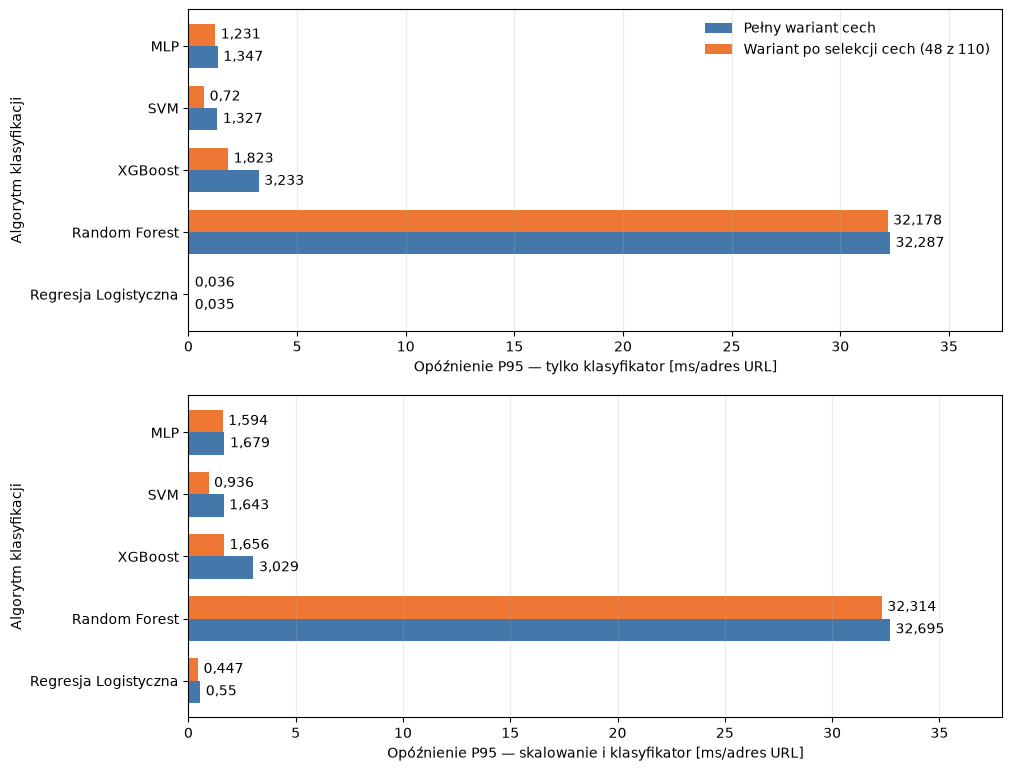

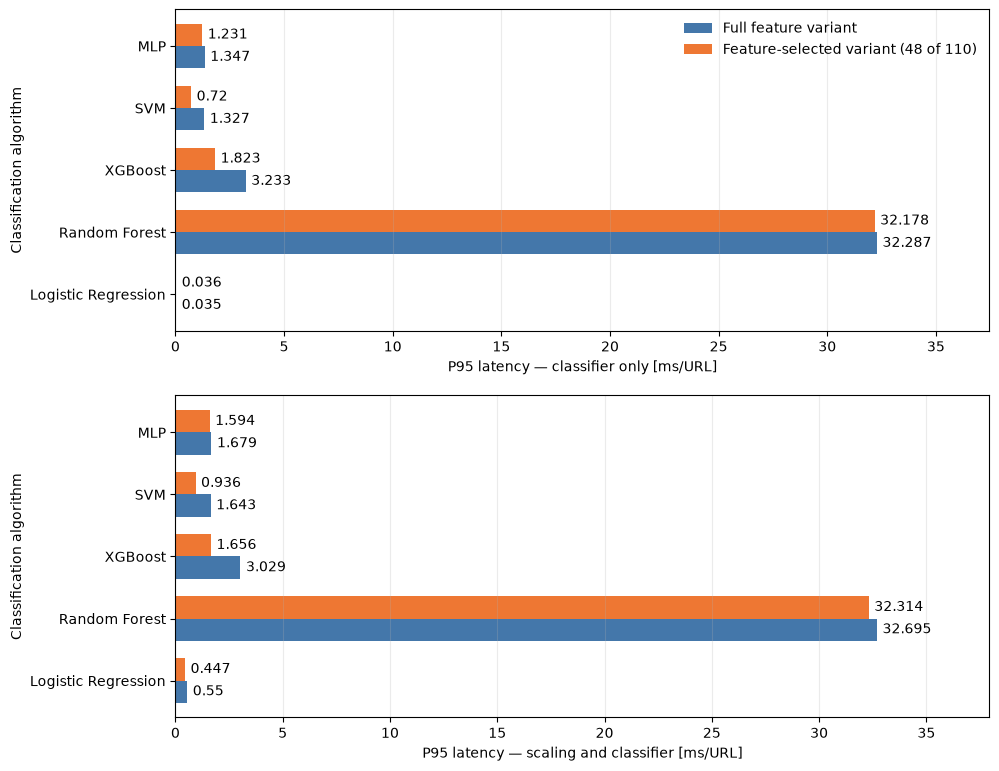

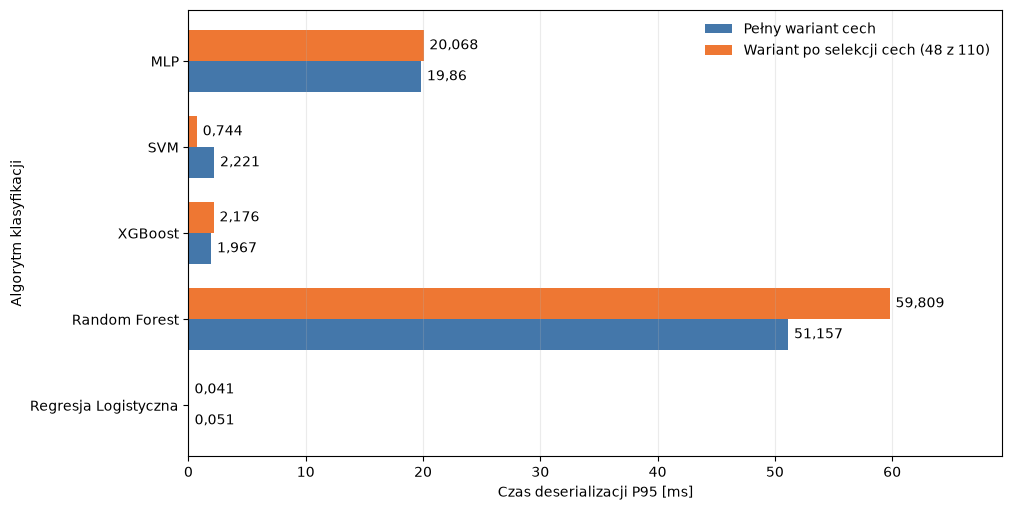

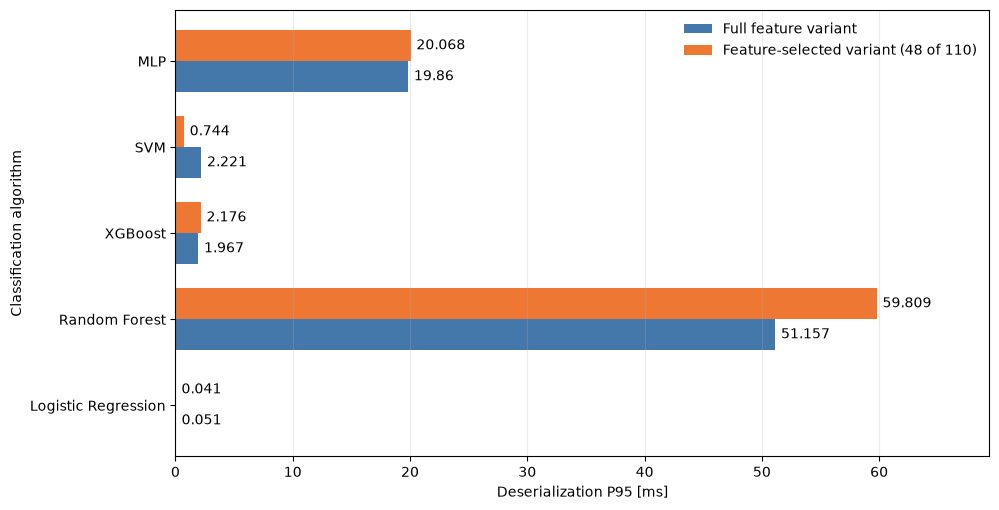

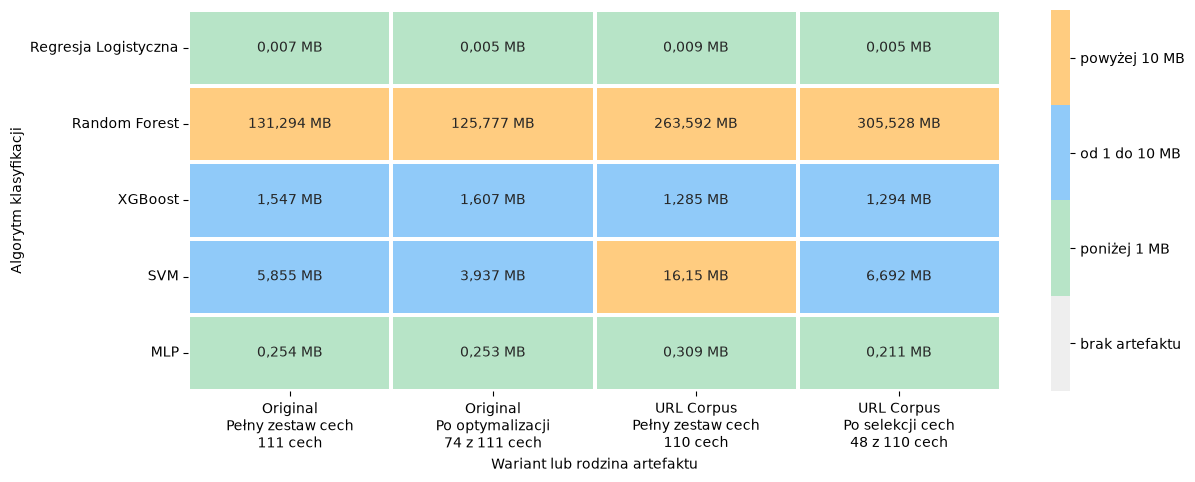

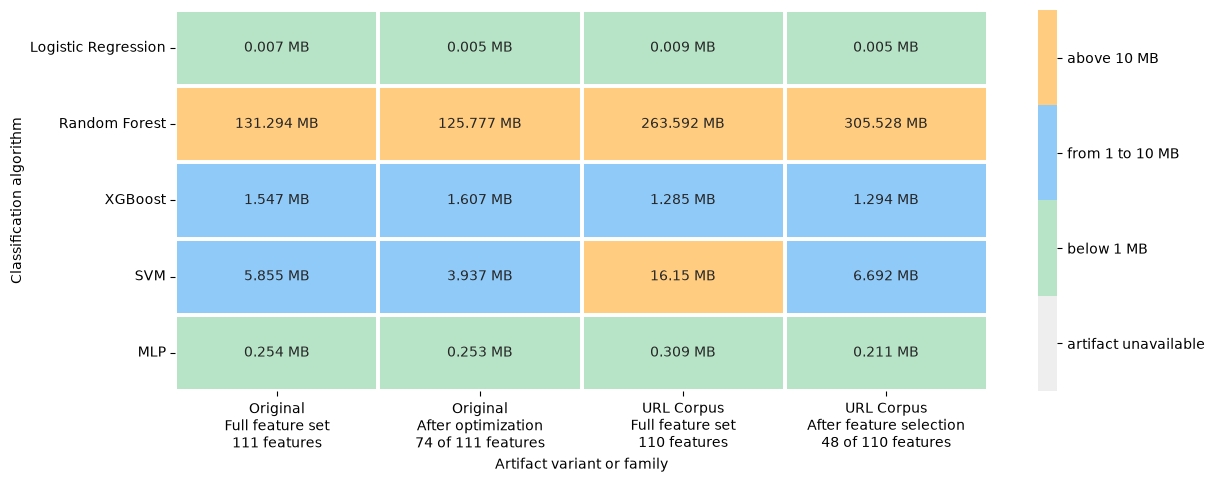

In [1]:
artifact_groups = {
    family: pd.read_csv(
        RESULTS_ROOT / family / 'runtime_complexity' / 'deserialization_timing_summary.csv'
    )
    for family in ('original', 'url_corpus')
}
plot_runtime_results(
    runtime_summary, load_summary, OUTPUT_DIR, MODEL_LABELS, artifact_groups
)
batch_one = runtime_summary[runtime_summary['batch_size'] == 1].copy()


## Zasady interpretacji

- mediana opisuje typowy czas, P95 — opóźnienie graniczne dla 95% wywołań;
- `ms/URL` i `URL/s` pozwalają porównać partie o różnej wielkości;
- wynik `classifier-only` izoluje algorytm, a drugi pomiar pokazuje koszt jego wymaganego przygotowania danych;
- rozmiar artefaktu i deserializacja wpływają na cold-start, lecz nie należy utożsamiać ich ze złożonością obliczeniową predykcji;
- miary strukturalne różnych rodzin algorytmów nie tworzą jednej wspólnej skali.

In [8]:
fastest = (
    batch_one[batch_one['scope'] == 'scaler_and_classifier']
    .sort_values('p95_ms')
    .iloc[0]
)
smallest = load_summary.sort_values('artifact_bytes').iloc[0]
print(
    f"Najniższe P95 dla jednej URL: {MODEL_LABELS[fastest['algorithm']]} "
    f"({fastest['mode']}), {fastest['p95_ms']:.4f} ms."
)
print(
    f"Najmniejszy artefakt: {MODEL_LABELS[smallest['algorithm']]} "
    f"({smallest['mode']}), {smallest['artifact_bytes'] / 1_000_000:.3f} MB."
)
print('Wnioski dotyczą wyłącznie artefaktów staged_url_corpus_v4 i tego środowiska.')


Najniższe P95 dla jednej URL: Regresja Logistyczna (selected), 0.4467 ms.
Najmniejszy artefakt: Regresja Logistyczna (selected), 0.005 MB.
Wnioski dotyczą wyłącznie artefaktów staged_url_corpus_v4 i tego środowiska.
